# Model Building and Evaluation

## Project: Credit Risk Analytics — Predicting Credit Card Default

### 4.1 Introduction

This phase focuses on developing and evaluating machine learning classification models to predict whether a credit card client will default on their next payment.

The original dataset and preprocessing decisions established in the previous phases will be reproduced independently in this notebook.

### Objectives

1. Establish a baseline using a DummyClassifier.
2. Train Logistic Regression as an initial predictive model.
3. Experiment with tree-based classification algorithms.
4. Evaluate models using multiple classification metrics.
5. Analyze confusion matrices and ROC curves.
6. Compare model performance and identify a suitable candidate.

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix

Particular attention will be given to recall and precision for the default class because identifying potential defaulters is a central objective of this classification problem.

### 4.2 Importing Required Libraries

The required Python libraries will be imported for data manipulation, visualization, preprocessing, model development and evaluation.

Scikit-learn will provide the classification algorithms, preprocessing transformers and evaluation metrics.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PowerTransformer
)

# Machine learning pipeline
from sklearn.pipeline import Pipeline

# Baseline classification
from sklearn.dummy import DummyClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully.")

All required libraries imported successfully.


### 4.3 Loading and Validating the Dataset

The original UCI Default of Credit Card Clients dataset will be loaded from the project's data directory.

The Excel file contains its actual column names in the first row, so the headers will be corrected before further processing.

The dataset will then be checked for its dimensions, data types, missing values and duplicate records.

In [5]:
# Define dataset path
DATA_PATH = Path("../data/default of credit card clients.xls")

# Load original Excel dataset
df_raw = pd.read_excel(DATA_PATH)

# Create working dataset
df = df_raw.copy()

# Correct column headers
df.columns = df.iloc[0].astype(str).str.strip()

# Remove the original header row
df = df.iloc[1:].reset_index(drop=True)

# Convert columns to numeric data types
df = df.apply(pd.to_numeric)

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes.value_counts())

print("\nMissing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("\nFirst Five Records:")
display(df.head())

Dataset Shape: (30000, 25)

Data Types:
int64    25
Name: count, dtype: int64

Missing Values: 0
Duplicate Rows: 0

First Five Records:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 4.4 Standardizing Categorical Values

The previous preprocessing phase identified undocumented and unknown category codes.

The same decisions will be reproduced:

- EDUCATION codes 0, 5 and 6 will be grouped with category 4.
- MARRIAGE code 0 will be grouped with category 3.
- SEX will remain unchanged.

These transformations will preserve all 30,000 observations.

In [6]:
# Create a separate processed dataset
df_processed = df.copy()

# Standardize education categories
df_processed["EDUCATION"] = df_processed["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4
})

# Standardize marriage categories
df_processed["MARRIAGE"] = df_processed["MARRIAGE"].replace({
    0: 3
})

# Verify standardized categories
for column in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{column} Distribution:")
    print(df_processed[column].value_counts().sort_index())

print("\nProcessed Dataset Shape:", df_processed.shape)


SEX Distribution:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION Distribution:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE Distribution:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64

Processed Dataset Shape: (30000, 25)


### 4.5 Feature Selection and Target Separation

The dataset contains 25 columns:

- 1 identifier column: ID
- 23 predictor features
- 1 target variable: default payment next month

The ID column will be excluded because it does not represent a meaningful financial or demographic characteristic.

The remaining 23 predictor features will be divided into appropriate feature groups for preprocessing.

In [8]:
# Define nominal categorical features
nominal_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

# Define repayment status features
repayment_features = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

# Define billing and payment amount features
billing_columns = [
    f"BILL_AMT{i}" for i in range(1, 7)
]

payment_columns = [
    f"PAY_AMT{i}" for i in range(1, 7)
]

amount_columns = billing_columns + payment_columns

# Define other numerical features
demographic_features = ["AGE"]
financial_features = ["LIMIT_BAL"]

# Combine predictor features
feature_columns = (
    nominal_features
    + repayment_features
    + financial_features
    + amount_columns
    + demographic_features
)

# Define target
target_column = "default payment next month"

# Separate features and target
X = df_processed[feature_columns].copy()
y = df_processed[target_column].copy()

# Verify feature selection
print("Number of Predictor Features:", len(feature_columns))
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts().sort_index())

Number of Predictor Features: 23
Feature Matrix Shape: (30000, 23)
Target Shape: (30000,)

Target Distribution:
default payment next month
0    23364
1     6636
Name: count, dtype: int64


### 4.6 Splitting the Dataset

The dataset will be divided into training and testing subsets using an 80:20 ratio.

Stratified sampling will preserve the original target-class distribution in both subsets.

A random state of 42 will ensure reproducibility and consistency with the previous preprocessing phase.

In [9]:
# Split dataset into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training Features: (24000, 23)
Testing Features: (6000, 23)

Training Target Distribution:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

Testing Target Distribution:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


### 4.7 Building the Preprocessing Pipeline

A ColumnTransformer will apply appropriate transformations to different feature groups.

- Nominal categorical features: OneHotEncoder.
- Repayment status features: OneHotEncoder.
- AGE and LIMIT_BAL: StandardScaler.
- Billing and payment amounts: Yeo-Johnson transformation followed by StandardScaler.

The preprocessing pipeline will be integrated into each predictive model.

This ensures that transformations are fitted only on the training data and prevents data leakage during model evaluation.

In [10]:
# Define categorical feature groups
categorical_features = nominal_features + repayment_features

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Standard numerical preprocessing
standard_numeric_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Skewed numerical preprocessing
amount_pipeline = Pipeline(steps=[
    ("power_transform", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

# Combine preprocessing operations
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_pipeline, categorical_features),
        ("standard_numeric", standard_numeric_pipeline,
         demographic_features + financial_features),
        ("amounts", amount_pipeline, amount_columns)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")
print("Original predictor features:", len(feature_columns))

Preprocessing pipeline created successfully.
Original predictor features: 23


### 4.8 Baseline Model — Dummy Classifier

A DummyClassifier will establish the minimum performance benchmark for the classification task.

The model will use the most_frequent strategy, which always predicts the majority class.

Since non-default clients represent 77.88% of the dataset, the classifier is expected to predict every client as non-default.

The baseline will be trained directly on the training labels without applying feature preprocessing because it does not use predictor features.

In [11]:
# Initialize baseline classifier
baseline_model = DummyClassifier(strategy="most_frequent")

# Train using training labels
baseline_model.fit(X_train, y_train)

# Generate predictions
y_pred_baseline = baseline_model.predict(X_test)

# Generate default-class probabilities
y_prob_baseline = baseline_model.predict_proba(X_test)[:, 1]

print("Baseline model trained successfully.")
print("Unique Predicted Classes:", np.unique(y_pred_baseline))
print("Total Predictions:", len(y_pred_baseline))

Baseline model trained successfully.
Unique Predicted Classes: [0]
Total Predictions: 6000


### 4.9 Evaluating the Baseline Model

The baseline classifier will be evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

A classification report and confusion matrix will provide additional information about its performance.

Particular attention will be given to the model's ability to identify defaulting clients.

In [12]:
# Calculate baseline evaluation metrics
baseline_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_baseline),
    "Precision": precision_score(
        y_test, y_pred_baseline, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_baseline, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_baseline, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob_baseline)
}

# Create baseline results table
baseline_results = pd.DataFrame(
    [baseline_metrics],
    index=["Dummy Classifier"]
)

display(baseline_results.round(4))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=["No Default", "Default"],
    zero_division=0
))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Dummy Classifier,0.7788,0.0,0.0,0.0,0.5



Classification Report:
              precision    recall  f1-score   support

  No Default       0.78      1.00      0.88      4673
     Default       0.00      0.00      0.00      1327

    accuracy                           0.78      6000
   macro avg       0.39      0.50      0.44      6000
weighted avg       0.61      0.78      0.68      6000


Confusion Matrix:
[[4673    0]
 [1327    0]]


### 4.10 Baseline Model — Findings

The DummyClassifier achieved an accuracy of 77.88%, which corresponds to the proportion of non-default clients in the test dataset.

However, the model predicted every observation as non-default.

Key findings:

- Accuracy: 77.88%
- Default-class precision: 0.00%
- Default-class recall: 0.00%
- Default-class F1-score: 0.00%
- ROC-AUC: 0.50
- True negatives: 4,673
- False negatives: 1,327
- True positives: 0
- False positives: 0

### Conclusion

The baseline model demonstrates that high accuracy does not necessarily indicate useful predictive performance in an imbalanced classification problem.

The model fails to identify any defaulting clients.

More advanced classification algorithms must improve default-class detection while maintaining an acceptable balance between precision and recall.

### 4.11 Logistic Regression Classification

Logistic Regression will be trained as the first predictive machine learning model.

It estimates the probability of a client defaulting on their next payment using a logistic function.

The model will use the previously defined preprocessing pipeline to encode categorical variables and transform numerical features.

The class_weight="balanced" parameter will compensate for the unequal distribution of default and non-default observations by assigning greater weight to the minority class.

A maximum of 1,000 iterations will be allowed to support model convergence.

In [13]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions
y_pred_logistic = logistic_model.predict(X_test)

# Generate default-class probabilities
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [14]:
# Calculate evaluation metrics
logistic_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_logistic),
    "Precision": precision_score(y_test, y_pred_logistic),
    "Recall": recall_score(y_test, y_pred_logistic),
    "F1-Score": f1_score(y_test, y_pred_logistic),
    "ROC-AUC": roc_auc_score(y_test, y_prob_logistic)
}

# Display results
logistic_results = pd.DataFrame(
    [logistic_metrics],
    index=["Logistic Regression"]
)

display(logistic_results.round(4))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["No Default", "Default"]
))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.764,0.4737,0.6051,0.5314,0.7708



Classification Report:
              precision    recall  f1-score   support

  No Default       0.88      0.81      0.84      4673
     Default       0.47      0.61      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.76      0.77      6000


Confusion Matrix:
[[3781  892]
 [ 524  803]]


### 4.12 Visualizing Logistic Regression Performance

The Logistic Regression model's classification performance will be visualized using a confusion matrix and a Receiver Operating Characteristic (ROC) curve.

The confusion matrix illustrates correct and incorrect predictions for both classes.

The ROC curve evaluates the model's ability to distinguish between defaulting and non-defaulting clients across different classification thresholds.

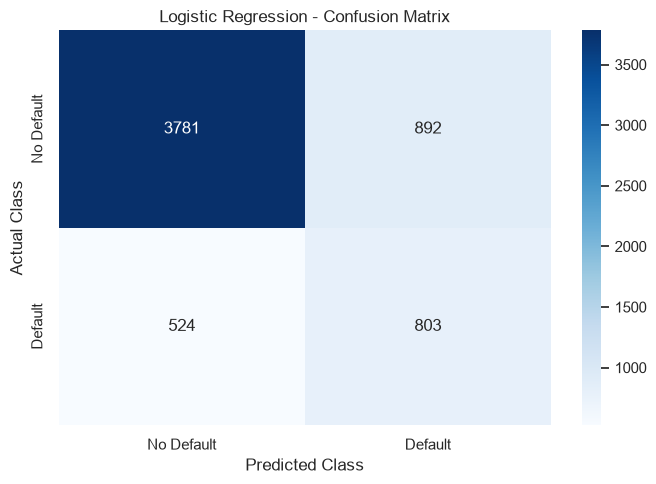

In [15]:
# Generate confusion matrix
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

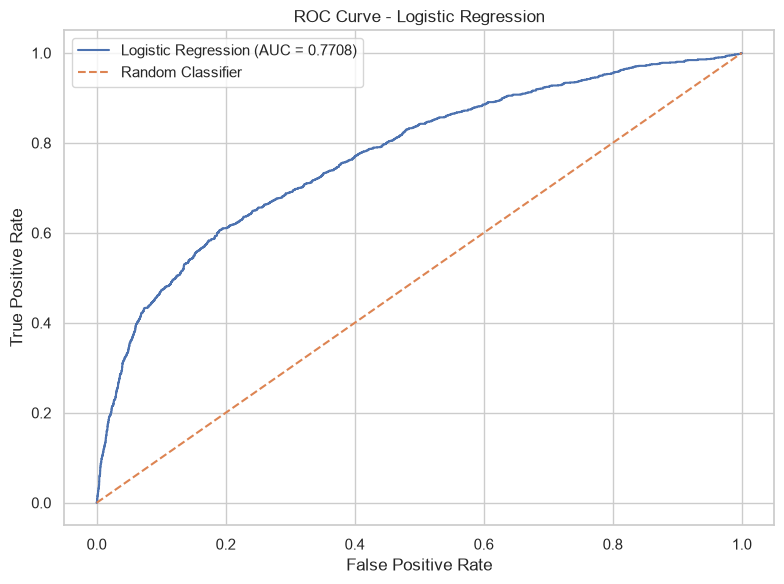

In [16]:
from sklearn.metrics import roc_curve

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob_logistic)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_logistic):.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

### 4.15 Logistic Regression — Initial Assessment

Logistic Regression achieved a ROC-AUC of 0.7708 and identified 60.51% of actual defaulters at the default classification threshold.

Compared with the DummyClassifier, it demonstrated substantially better predictive capability.

However, the model produced 892 false positives and 524 false negatives.

These results indicate that further experimentation with nonlinear classification algorithms and classification thresholds is required.

Logistic Regression will be retained as the initial predictive benchmark for subsequent model comparisons.

### 4.16 Decision Tree Classification

A Decision Tree Classifier will be developed to identify nonlinear relationships between financial characteristics, repayment behaviour and credit card default.

Unlike Logistic Regression, a Decision Tree uses a sequence of feature-based splitting rules to classify observations.

The model will use:

- Gini impurity as the splitting criterion.
- Maximum tree depth of 8 to control complexity.
- Balanced class weights to address target imbalance.
- Random state of 42 for reproducibility.

The preprocessing pipeline will be integrated into the model to ensure consistent feature transformations.

In [17]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Generate predictions
y_pred_tree = decision_tree_model.predict(X_test)

# Generate default-class probabilities
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree training completed.")

Decision Tree training completed.


In [18]:
# Calculate evaluation metrics
tree_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_tree),
    "Precision": precision_score(y_test, y_pred_tree),
    "Recall": recall_score(y_test, y_pred_tree),
    "F1-Score": f1_score(y_test, y_pred_tree),
    "ROC-AUC": roc_auc_score(y_test, y_prob_tree)
}

# Display evaluation results
tree_results = pd.DataFrame(
    [tree_metrics],
    index=["Decision Tree"]
)

display(tree_results.round(4))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["No Default", "Default"]
))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Decision Tree,0.7448,0.4429,0.5961,0.5082,0.7444



Classification Report:
              precision    recall  f1-score   support

  No Default       0.87      0.79      0.83      4673
     Default       0.44      0.60      0.51      1327

    accuracy                           0.74      6000
   macro avg       0.66      0.69      0.67      6000
weighted avg       0.78      0.74      0.76      6000


Confusion Matrix:
[[3678  995]
 [ 536  791]]


### 4.20 Decision Tree — Initial Assessment

The Decision Tree Classifier achieved:

- Accuracy: 74.48%
- Precision: 44.29%
- Recall: 59.61%
- F1-score: 50.82%
- ROC-AUC: 0.7444

The model correctly identified 791 defaulting clients but missed 536 actual defaulters.

Compared with Logistic Regression, the Decision Tree produced lower performance across all five evaluation metrics.

The current Decision Tree configuration will be retained as an experimental benchmark. Further hyperparameter tuning may be considered later.

### 4.21 Random Forest Classification

A Random Forest Classifier will be developed using an ensemble of decision trees.

Each tree is trained using a random sample of observations and features. Their predictions are combined to produce the final classification.

The initial configuration will use:

- 200 decision trees.
- Maximum tree depth of 12.
- Balanced class weights.
- Random state of 42.
- Parallel processing using all available CPU cores.

The model will use the existing preprocessing pipeline and will be evaluated using the same classification metrics as previous models.

In [19]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)

# Generate default-class probabilities
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest training completed.")

Random Forest training completed.


In [20]:
# Calculate evaluation metrics
rf_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1-Score": f1_score(y_test, y_pred_rf),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
}

# Display evaluation results
rf_results = pd.DataFrame(
    [rf_metrics],
    index=["Random Forest"]
)

display(rf_results.round(4))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Default", "Default"]
))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Random Forest,0.7817,0.5056,0.5818,0.541,0.7762



Classification Report:
              precision    recall  f1-score   support

  No Default       0.88      0.84      0.86      4673
     Default       0.51      0.58      0.54      1327

    accuracy                           0.78      6000
   macro avg       0.69      0.71      0.70      6000
weighted avg       0.79      0.78      0.79      6000


Confusion Matrix:
[[3918  755]
 [ 555  772]]


### 4.22 Random Forest — Initial Assessment

The Random Forest Classifier achieved:

- Accuracy: 78.17%
- Precision: 50.56%
- Recall: 58.18%
- F1-score: 54.10%
- ROC-AUC: 0.7762

The model correctly identified 772 defaulting clients and missed 555 actual defaulters.

Compared with Logistic Regression, Random Forest demonstrated higher accuracy, precision, F1-score and ROC-AUC, but slightly lower recall.

Compared with the single Decision Tree, Random Forest improved performance across all five evaluation metrics.

### Conclusion

Random Forest is currently the strongest overall model based on the evaluated metrics.

However, Logistic Regression remains preferable when maximizing default-class recall is the primary objective.

Further experimentation with boosting algorithms and classification thresholds will help determine whether predictive performance can be improved.

### 4.23 Gradient Boosting Classification

A Gradient Boosting Classifier will be developed as another ensemble learning approach.

Unlike Random Forest, which trains trees independently, Gradient Boosting builds trees sequentially. Each new tree attempts to reduce the errors made by the existing ensemble.

The initial configuration will use:

- 100 boosting stages.
- Learning rate of 0.05.
- Maximum tree depth of 3.
- Random state of 42.

The model will use the existing preprocessing pipeline and the same evaluation metrics for a fair comparison.

In [21]:
from sklearn.ensemble import GradientBoostingClassifier

# Create Gradient Boosting pipeline
gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gradient_boosting_model.fit(X_train, y_train)

# Generate predictions
y_pred_gb = gradient_boosting_model.predict(X_test)

# Generate default-class probabilities
y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [22]:
# Calculate evaluation metrics
gb_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_gb),
    "Precision": precision_score(y_test, y_pred_gb),
    "Recall": recall_score(y_test, y_pred_gb),
    "F1-Score": f1_score(y_test, y_pred_gb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_gb)
}

# Display evaluation results
gb_results = pd.DataFrame(
    [gb_metrics],
    index=["Gradient Boosting"]
)

display(gb_results.round(4))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["No Default", "Default"]
))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Gradient Boosting,0.8157,0.6647,0.3361,0.4464,0.7745



Classification Report:
              precision    recall  f1-score   support

  No Default       0.83      0.95      0.89      4673
     Default       0.66      0.34      0.45      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.64      0.67      6000
weighted avg       0.80      0.82      0.79      6000


Confusion Matrix:
[[4448  225]
 [ 881  446]]


### 4.24 Gradient Boosting — Initial Assessment

The Gradient Boosting Classifier achieved:

- Accuracy: 81.57%
- Precision: 66.47%
- Recall: 33.61%
- F1-score: 44.64%
- ROC-AUC: 0.7745

The model achieved the highest accuracy and precision among the evaluated models.

However, its default-class recall was considerably lower than that of Logistic Regression, Decision Tree and Random Forest.

This indicates that the model is conservative when predicting default and misses a substantial proportion of actual defaulters.

### Conclusion

Gradient Boosting demonstrates strong overall classification accuracy and precision, but its default-class recall requires improvement.

It will remain part of the model comparison rather than being selected solely on accuracy.

### 4.25 Comparative Evaluation of Classification Models

The four predictive models and the DummyClassifier baseline will be compared using a common set of evaluation metrics.

The comparison will examine:

- Accuracy: Overall classification correctness.
- Precision: Reliability of default predictions.
- Recall: Proportion of actual defaulters identified.
- F1-score: Balance between precision and recall.
- ROC-AUC: Ability to distinguish between the two classes.

The results will be used to identify the strongest candidate for further experimentation.

In [23]:
# Combine evaluation metrics from all models
model_comparison = pd.DataFrame({
    "Dummy Classifier": baseline_metrics,
    "Logistic Regression": logistic_metrics,
    "Decision Tree": tree_metrics,
    "Random Forest": rf_metrics,
    "Gradient Boosting": gb_metrics
}).T

# Display comparison table
display(model_comparison.round(4))

# Identify the best model for each metric
print("\nBest Model by Evaluation Metric:")

for metric in model_comparison.columns:
    best_model = model_comparison[metric].idxmax()
    best_score = model_comparison[metric].max()

    print(f"{metric}: {best_model} ({best_score:.4f})")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Dummy Classifier,0.7788,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.7640,0.4737,0.6051,0.5314,0.7708
Decision Tree,0.7448,0.4429,0.5961,0.5082,0.7444
Random Forest,0.7817,0.5056,0.5818,0.5410,0.7762
Gradient Boosting,0.8157,0.6647,0.3361,0.4464,0.7745



Best Model by Evaluation Metric:
Accuracy: Gradient Boosting (0.8157)
Precision: Gradient Boosting (0.6647)
Recall: Logistic Regression (0.6051)
F1-Score: Random Forest (0.5410)
ROC-AUC: Random Forest (0.7762)


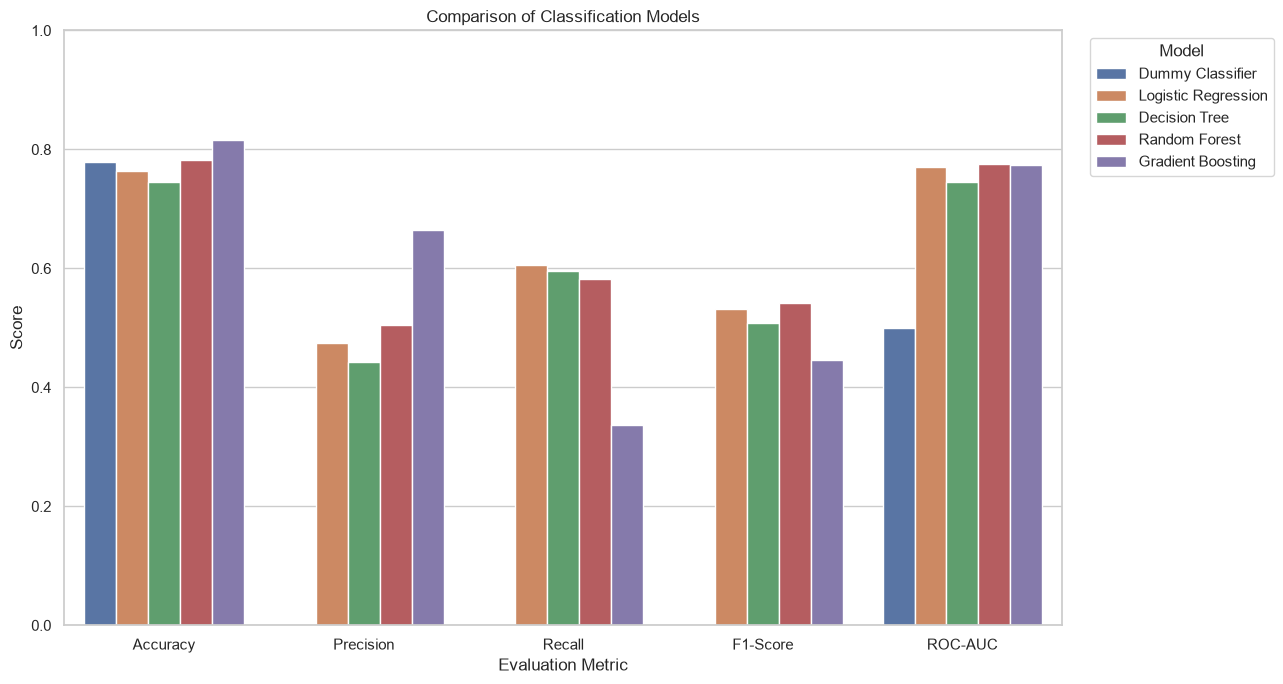

In [24]:
# Prepare comparison data for visualization
comparison_plot = model_comparison.reset_index().rename(
    columns={"index": "Model"}
)

# Convert metrics into long format
comparison_long = comparison_plot.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

# Plot model performance
plt.figure(figsize=(13, 7))

sns.barplot(
    data=comparison_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 4.26 Validation Split for Classification Threshold Tuning

A separate validation subset will be created from the existing training data.

The original test dataset will remain untouched until final model evaluation.

The training data will be divided into:

- Model-training subset: 80% of the original training data.
- Validation subset: 20% of the original training data.

Stratified sampling will preserve the target-class distribution.

Threshold selection will be based on validation performance, using precision, recall and F1-score. The F1-score will provide an initial balanced selection criterion, while recall and precision will also be considered.

In [25]:
from sklearn.base import clone

# Divide existing training data into model-training and validation subsets
X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model Training Features:", X_subtrain.shape)
print("Validation Features:", X_validation.shape)

print("\nModel Training Target Distribution:")
print(y_subtrain.value_counts(normalize=True).mul(100).round(2))

print("\nValidation Target Distribution:")
print(y_validation.value_counts(normalize=True).mul(100).round(2))

Model Training Features: (19200, 23)
Validation Features: (4800, 23)

Model Training Target Distribution:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

Validation Target Distribution:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


### 4.27 Training Candidate Models for Threshold Selection

Logistic Regression, Random Forest and Gradient Boosting will be retrained using only the model-training subset.

Their predicted default probabilities will be generated for the validation subset.

The previously trained models will remain unchanged. Cloned pipelines will be used to create independent validation models.

In [27]:
# Create independent copies of the candidate models
validation_models = {
    "Logistic Regression": clone(logistic_model),
    "Random Forest": clone(random_forest_model),
    "Gradient Boosting": clone(gradient_boosting_model)
}

# Train models and generate validation probabilities
validation_probabilities = {}

for model_name, model in validation_models.items():
    model.fit(X_subtrain, y_subtrain)

    validation_probabilities[model_name] = (
        model.predict_proba(X_validation)[:, 1]
    )

    print(f"{model_name} validation predictions generated.")

Logistic Regression validation predictions generated.
Random Forest validation predictions generated.
Gradient Boosting validation predictions generated.


### 4.28 Classification Threshold Evaluation

Multiple classification thresholds will be evaluated using validation probabilities.

For each threshold, the following metrics will be calculated for the default class:

- Precision
- Recall
- F1-score

The comparison will help identify how changing the classification threshold affects the balance between detecting defaulters and incorrectly flagging non-defaulters.

The test dataset will not be used during this selection process.

In [28]:
# Define thresholds to evaluate
thresholds = np.arange(0.20, 0.61, 0.05)

threshold_results = []

# Evaluate each model at each threshold
for model_name, probabilities in validation_probabilities.items():

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_validation, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_validation, predictions, zero_division=0
            ),
            "F1-Score": f1_score(
                y_validation, predictions, zero_division=0
            )
        })

threshold_results = pd.DataFrame(threshold_results)

display(
    threshold_results.round(4).sort_values(
        ["Model", "Threshold"]
    ).reset_index(drop=True)
)

,Model,Threshold,Precision,Recall,F1-Score
0,Gradient Boosting,0.20,0.4410,0.6441,0.5235
1,Gradient Boosting,0.25,0.5122,0.5716,0.5403
2,Gradient Boosting,0.30,0.5690,0.4699,0.5147
3,Gradient Boosting,0.35,0.6099,0.4313,0.5052
4,Gradient Boosting,0.40,0.6417,0.4030,0.4951
5,Gradient Boosting,0.45,0.6655,0.3691,0.4749
6,Gradient Boosting,0.50,0.6698,0.3343,0.4460
7,Gradient Boosting,0.55,0.6958,0.3145,0.4332
8,Gradient Boosting,0.60,0.7160,0.2778,0.4003
9,Logistic Regression,0.20,0.2381,0.9689,0.3822


In [29]:
# Identify the threshold with the highest validation F1-score for each model
best_threshold_indices = threshold_results.groupby("Model")[
    "F1-Score"
].idxmax()

best_thresholds = threshold_results.loc[
    best_threshold_indices
].sort_values("F1-Score", ascending=False).reset_index(drop=True)

display(best_thresholds.round(4))

,Model,Threshold,Precision,Recall,F1-Score
0,Gradient Boosting,0.25,0.5122,0.5716,0.5403
1,Random Forest,0.55,0.5422,0.5264,0.5342
2,Logistic Regression,0.55,0.5087,0.5527,0.5298


### 4.29 Selected Classification Thresholds

The validation results were used to select classification thresholds by maximizing the F1-score for the default class.

The selected thresholds are:

- Gradient Boosting: 0.25
- Random Forest: 0.55
- Logistic Regression: 0.55

Gradient Boosting achieved the highest validation F1-score of 0.5403 at a threshold of 0.25.

At this threshold, its default-class recall increased to 57.16%, compared with 33.43% at a threshold of 0.50.

Random Forest achieved a validation F1-score of 0.5342 at a threshold of 0.55.

These thresholds were selected using validation data only. The independent test dataset remains reserved for final performance evaluation.

### 4.30 Final Evaluation of Threshold-Tuned Models

The selected thresholds will now be applied to predictions generated by models trained on the complete training dataset.

The models will be evaluated on the original untouched test dataset.

The evaluation will include accuracy, precision, recall, F1-score and ROC-AUC.

This final evaluation will determine whether the improvements observed during validation generalize to unseen observations.

In [30]:
# Define selected thresholds
selected_thresholds = {
    "Logistic Regression": 0.55,
    "Random Forest": 0.55,
    "Gradient Boosting": 0.25
}

# Collect test probabilities from models trained on full training data
test_probabilities = {
    "Logistic Regression": y_prob_logistic,
    "Random Forest": y_prob_rf,
    "Gradient Boosting": y_prob_gb
}

# Evaluate each model using its selected threshold
tuned_results = []
tuned_predictions = {}

for model_name, threshold in selected_thresholds.items():

    probabilities = test_probabilities[model_name]

    predictions = (probabilities >= threshold).astype(int)

    tuned_predictions[model_name] = predictions

    tuned_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

# Create final comparison table
tuned_results = pd.DataFrame(tuned_results).set_index("Model")

display(tuned_results.round(4))

,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,,
Logistic Regression,0.55,0.7837,0.5103,0.5433,0.5263,0.7708
Random Forest,0.55,0.8015,0.5532,0.5328,0.5428,0.7762
Gradient Boosting,0.25,0.7878,0.5189,0.5599,0.5386,0.7745


In [31]:
# Display confusion matrices for threshold-tuned models
for model_name, predictions in tuned_predictions.items():

    print(f"\n{model_name} - Confusion Matrix")

    cm = confusion_matrix(y_test, predictions)

    display(pd.DataFrame(
        cm,
        index=["Actual No Default", "Actual Default"],
        columns=["Predicted No Default", "Predicted Default"]
    ))


Logistic Regression - Confusion Matrix


,Predicted No Default,Predicted Default
Actual No Default,3981,692
Actual Default,606,721



Random Forest - Confusion Matrix


,Predicted No Default,Predicted Default
Actual No Default,4102,571
Actual Default,620,707



Gradient Boosting - Confusion Matrix


,Predicted No Default,Predicted Default
Actual No Default,3984,689
Actual Default,584,743


### 4.31 Final Model Selection and Interpretation

The threshold-tuned models were evaluated using the independent test dataset.

Key findings:

**Random Forest (threshold = 0.55)**
- Accuracy: 80.15%
- Precision: 55.32%
- Recall: 53.28%
- F1-score: 54.28%
- ROC-AUC: 0.7762

Random Forest achieved the highest test accuracy, precision, F1-score and ROC-AUC among the three threshold-tuned models.

**Gradient Boosting (threshold = 0.25)**
- Accuracy: 78.78%
- Precision: 51.89%
- Recall: 55.99%
- F1-score: 53.86%
- ROC-AUC: 0.7745

Gradient Boosting identified the highest number of actual defaulters, achieving the best recall.

**Logistic Regression (threshold = 0.55)**
- Accuracy: 78.37%
- Precision: 51.03%
- Recall: 54.33%
- F1-score: 52.63%
- ROC-AUC: 0.7708

### Final Selection

Random Forest is selected as the leading balanced model because it achieved the highest test F1-score and ROC-AUC.

Gradient Boosting remains a strong alternative when maximizing default detection is prioritized.

The selection is based on the evaluated test results and does not imply that either model is suitable for real-world lending decisions without further validation.

### 4.32 Confusion Matrix Comparison

The confusion matrices of the threshold-tuned models will be visualized side by side.

This comparison will help identify differences in correctly classified defaulters, missed defaulters and incorrectly flagged non-defaulters.

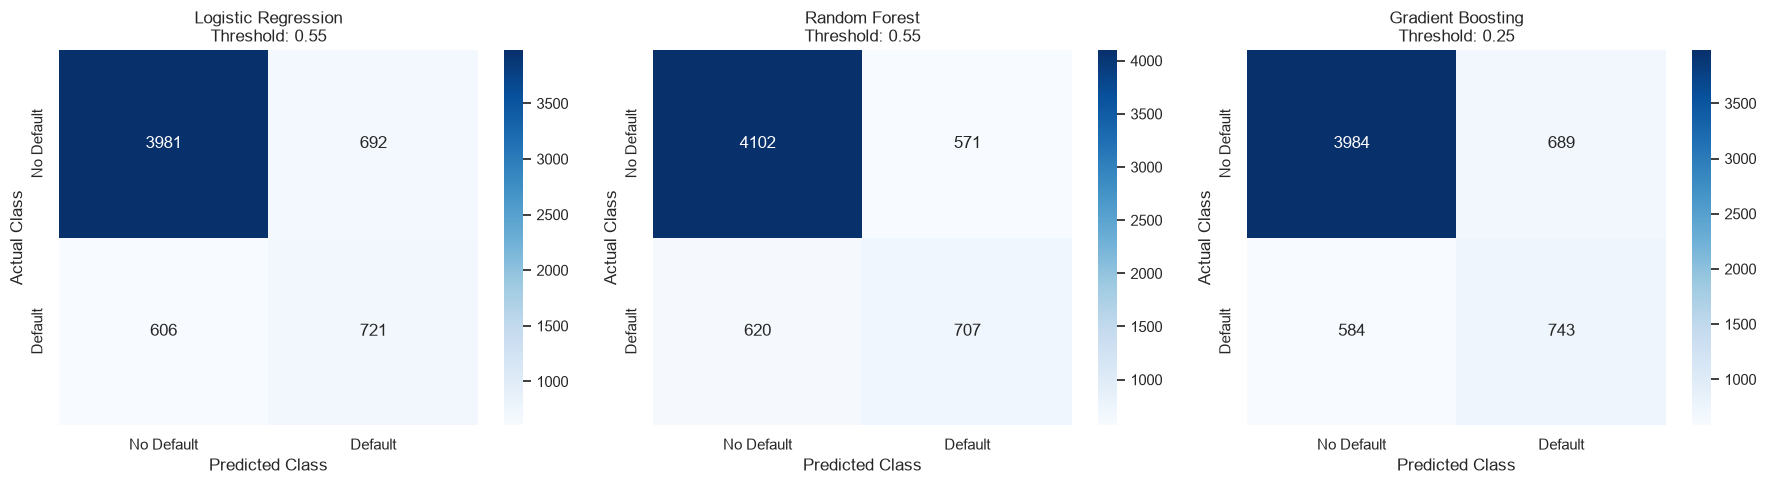

In [32]:
# Create side-by-side confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, predictions) in zip(
    axes, tuned_predictions.items()
):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Default", "Default"],
        yticklabels=["No Default", "Default"],
        ax=ax
    )

    ax.set_title(f"{model_name}\nThreshold: {selected_thresholds[model_name]}")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

### 4.33 ROC Curve Comparison

The ROC curves of Logistic Regression, Random Forest and Gradient Boosting will be plotted together.

ROC-AUC evaluates the ability of each model to distinguish between defaulting and non-defaulting clients across classification thresholds.

Unlike precision, recall and F1-score, ROC-AUC is calculated from predicted probabilities and does not change when the classification threshold changes.

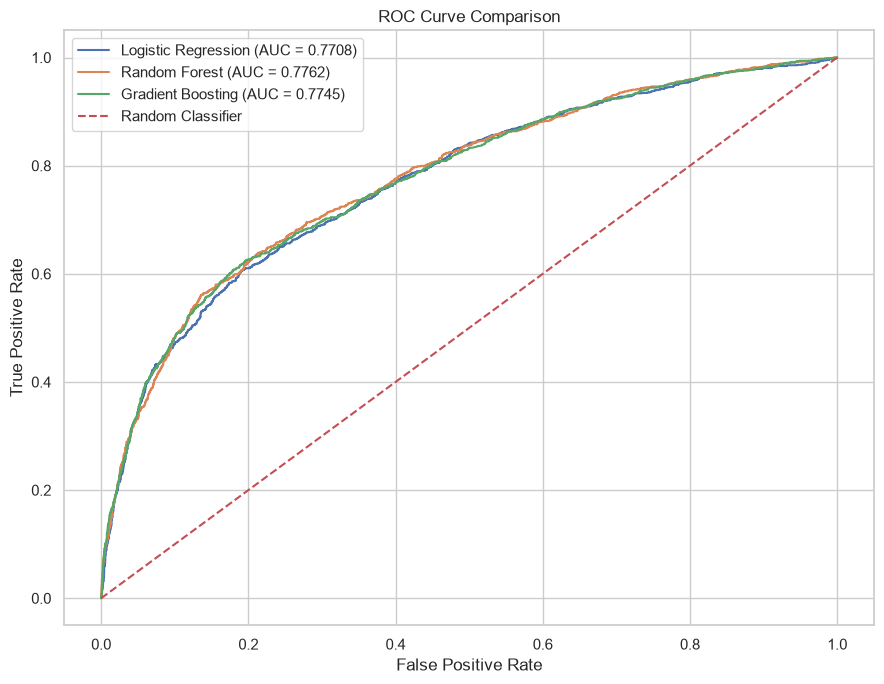

In [33]:
from sklearn.metrics import roc_curve

# Define model probabilities
roc_models = {
    "Logistic Regression": y_prob_logistic,
    "Random Forest": y_prob_rf,
    "Gradient Boosting": y_prob_gb
}

# Plot ROC curves
plt.figure(figsize=(9, 7))

for model_name, probabilities in roc_models.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)

    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

### 4.34 Feature Importance Analysis

Feature importance will be examined using the selected Random Forest model.

The model assigns an importance score to each transformed feature based on its contribution to reducing impurity across the decision trees.

The analysis will identify which demographic, financial and repayment-history variables contribute most to the model's predictions.

Feature importance indicates predictive contribution within this fitted model. It does not establish causation or the direction of a feature's relationship with default.

In [34]:
# Retrieve the fitted preprocessing transformer
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]

# Retrieve transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Retrieve Random Forest feature importance scores
importance_scores = (
    random_forest_model.named_steps["classifier"].feature_importances_
)

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
display(feature_importance.head(20).round(5))

,Feature,Importance
0,categorical__PAY_0_2,0.12125
1,categorical__PAY_2_2,0.06959
2,standard_numeric__LIMIT_BAL,0.04854
3,amounts__PAY_AMT1,0.04839
4,categorical__PAY_3_2,0.04424
5,categorical__PAY_0_0,0.04369
6,amounts__BILL_AMT1,0.04106
7,amounts__PAY_AMT2,0.04095
8,amounts__PAY_AMT3,0.03765
9,amounts__BILL_AMT2,0.03618


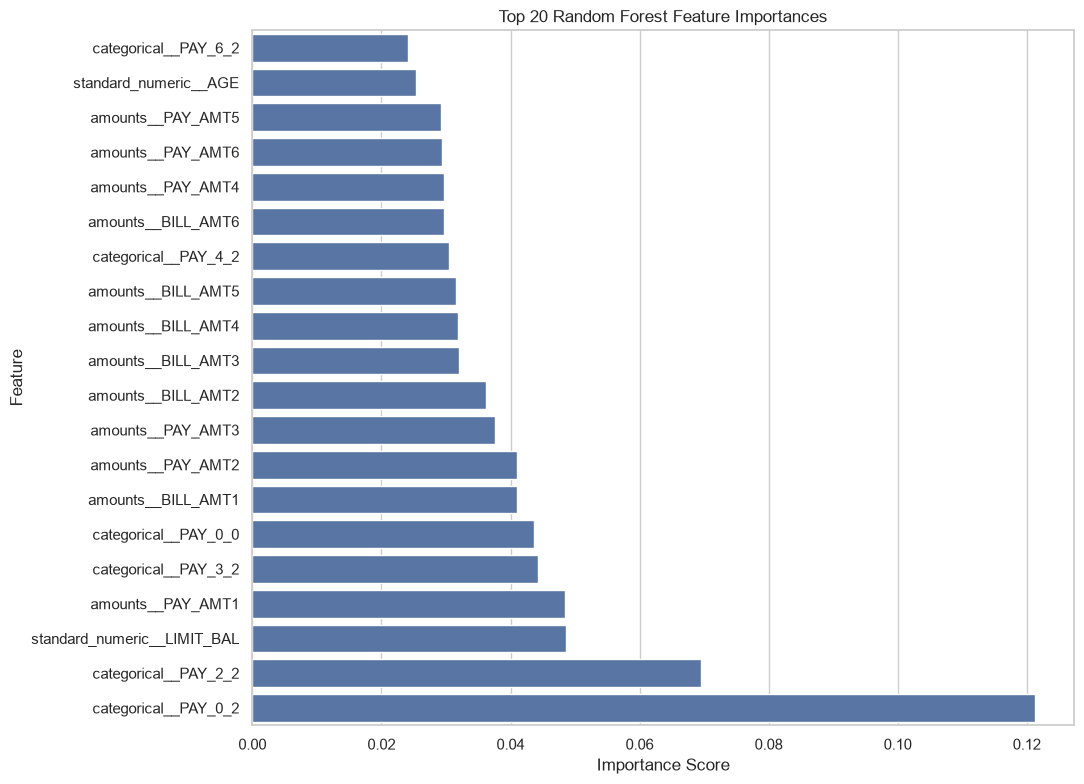

In [35]:
# Select the top 20 features
top_features = feature_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

# Plot feature importance
plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 4.35 Feature Importance — Findings

The Random Forest feature importance analysis identified repayment history as the strongest contributor to model predictions.

Key observations:

- PAY_0_2 has the highest importance score of 0.12125.
- PAY_2_2 ranks second with an importance score of 0.06959.
- LIMIT_BAL ranks third with an importance score of 0.04854.
- Recent payment amounts and billing amounts also contribute substantially.
- AGE has a comparatively lower importance score of 0.02530.

### Conclusion

Repayment behaviour appears to contain substantial predictive information for identifying potential credit card defaults.

Credit limits, payment amounts and billing amounts also contribute to the model's predictive performance.

These findings describe relationships learned by the Random Forest model and should not be interpreted as causal relationships.

### 4.36 Project Limitations

Despite the predictive performance achieved, several limitations must be considered.

1. **Dataset Age:** The dataset contains historical observations from Taiwan in 2005. Its patterns may not represent current credit markets.

2. **Geographical Limitation:** The dataset represents credit card clients from Taiwan and may not generalize to other countries.

3. **Class Imbalance:** Defaulting clients represent approximately 22.12% of the dataset, which affects classification performance.

4. **False Predictions:** Even the selected Random Forest model misses 620 actual defaulters at the selected threshold.

5. **Feature Importance:** Impurity-based feature importance does not establish causation and can be affected by correlated predictors.

6. **Model Generalization:** The models have been evaluated using one stratified train-test split. Additional cross-validation and external validation would provide stronger evidence of generalization.

7. **Threshold Trade-offs:** Increasing default detection can also increase false positive predictions, so classification thresholds depend on the intended application.

### Overall Limitation

The developed models are experimental predictive models based on a historical dataset. Their results should not be treated as evidence of suitability for real-world credit approval or lending decisions.

# 4.37 Final Conclusion

The Credit Risk Analytics project investigated historical credit card client data and developed machine learning classification models to predict next-month payment default.

The project included data understanding, exploratory data analysis, data preprocessing, feature engineering, model development and performance evaluation.

### Models Developed

1. Dummy Classifier
2. Logistic Regression
3. Decision Tree Classifier
4. Random Forest Classifier
5. Gradient Boosting Classifier

### Final Model Performance

Random Forest with a classification threshold of 0.55 achieved the strongest balanced performance among the threshold-tuned models.

- Accuracy: 80.15%
- Precision: 55.32%
- Recall: 53.28%
- F1-score: 54.28%
- ROC-AUC: 0.7762

Gradient Boosting with a threshold of 0.25 achieved the highest default-class recall of 55.99%.

### Key Research Findings

- Repayment history was the most influential feature group in the Random Forest model.
- Credit limits and payment amounts also contributed to prediction.
- Threshold adjustment improved the balance between precision and recall.
- Accuracy alone was insufficient for evaluating performance because of the imbalanced target distribution.

### Final Conclusion

The experiments demonstrate that historical repayment behaviour and financial characteristics can provide useful information for predicting credit card default.

Random Forest emerged as the strongest balanced candidate, while Gradient Boosting offered slightly better identification of defaulting clients at its selected threshold.

The project demonstrates a complete machine learning workflow, from raw dataset investigation to model evaluation and interpretation.